<a href="https://colab.research.google.com/github/sumitrac/SpaceExplore-Nasa-Space-Apps/blob/NASA-Hydrology-Sumitra/SpaceExplore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install pymannkendall


In [2]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import pymannkendall as mk

print("All set!")

All set!


In [3]:
from google.colab import userdata

class EarthdataSession(requests.Session):
    AUTH_HOST = "urs.earthdata.nasa.gov"

    def __init__(self, username, password):
        super().__init__()
        self.auth = (username, password)

    # Keep the login when NASA redirects to its login server
    def rebuild_auth(self, prepared_request, response):
        headers = prepared_request.headers
        if "Authorization" in headers:
            original = requests.utils.urlparse(response.request.url).hostname
            redirect = requests.utils.urlparse(prepared_request.url).hostname
            if (original != redirect and redirect != self.AUTH_HOST
                    and original != self.AUTH_HOST):
                del headers["Authorization"]

session = EarthdataSession(userdata.get("EARTHDATA_USER"),
                           userdata.get("EARTHDATA_PASS"))
print("Session ready!")

Session ready!


In [5]:
from google.colab import userdata

token = userdata.get("EARTHDATA_TOKEN")
print("Token loaded!" if token else "Token missing")
print("Length:", len(token))

Token loaded!
Length: 696


In [6]:
# Settings for the request: what data, where, and when
params = {
    # Dataset + variable: NLDAS Noah hourly v2.0, snow water equivalent
    "data": "NLDAS_NOAH0125_H_2_0_SWE",

    # The point: latitude first, then longitude (Upper Cedar watershed)
    "location": "[47.32,-121.45]",

    # Time range: one water year for a quick test.
    # Later, change to "1979-01-02T00:00:00/2025-09-30T23:00:00"
    "time": "2020-10-01T00:00:00/2021-09-30T23:00:00",

    "version": "2.0",
}

# Send the token so NASA knows who's asking
headers = {"Authorization": f"Bearer {token}"}

# Ask NASA's Giovanni time series API for the data
response = requests.get("https://api.giovanni.earthdata.nasa.gov/timeseries",
                        params=params, headers=headers)

# 200 = success, 401 = login/token problem, 400 = bad request (e.g., wrong variable name)
print("Status:", response.status_code)

# Show the first 800 characters so we can check the format before using it
print(response.text[:800])

Status: 200
prod_name,NLDAS_NOAH0125_H.2.0
doi,10.5067/T4OW83T8EXDO
param_short_name,SWE
param_name,Snow Water Equivalent
unit,kg m-2
undef,-9999
begin_time,2020-10-01 00:00:00
end_time,2021-09-30 23:00:00
lat,47.3125
lon,-121.4375
lat_resolution,0.125
lon_resolution,0.125
mean,8.6404e+01
Request_time,2026-11-14 22:07:27

Timestamp (UTC),Data
2020-10-01 00:00,0
2020-10-01 01:00,0
2020-10-01 02:00,0
2020-10-01 03:00,0
2020-10-01 04:00,0
2020-10-01 05:00,0
2020-10-01 06:00,0
2020-10-01 07:00,0
2020-10-01 08:00,0
2020-10-01 09:00,0
2020-10-01 10:00,0
2020-10-01 11:00,0
2020-10-01 12:00,0
2020-10-01 13:00,0
2020-10-01 14:00,0
2020-10-01 15:00,0
2020-10-01 16:00,0
2020-10-01 17:00,0
2020-10-01 18:00,0
2020-10-01 19:00,0
2020-10-01 20:00,0
2020-10-01 21:00,0
2020-10-01 22:00,0
2020-10-01 23:00,0
2020-10-02 


                     swe_mm
time                       
2020-10-01 00:00:00     0.0
2020-10-01 01:00:00     0.0
2020-10-01 02:00:00     0.0
2020-10-01 03:00:00     0.0
2020-10-01 04:00:00     0.0
Rows: 8760
Missing values: 0


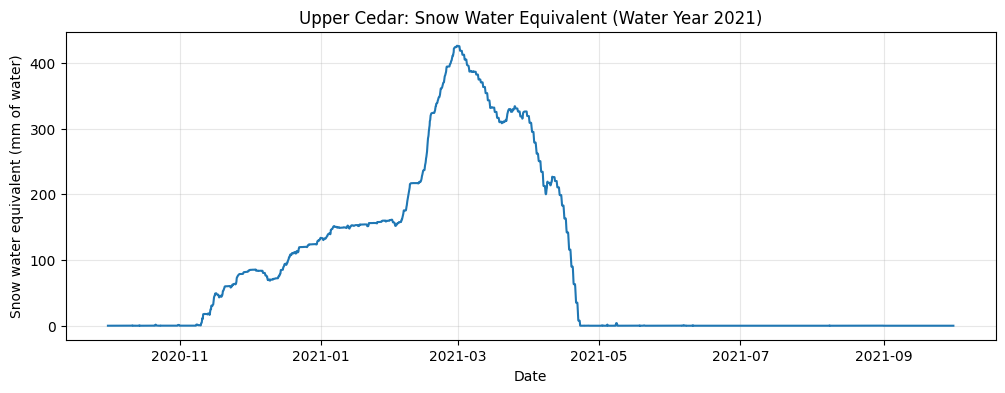

In [7]:
from io import StringIO   # lets pandas read text as if it were a file

# --- Step 5: Turn the text into a table ---

# The response has header info first, then the data.
# Find the line where the data starts ("Timestamp (UTC),Data").
lines = response.text.splitlines()
start = next(i for i, line in enumerate(lines) if line.startswith("Timestamp"))

# Read everything from that line onward into a pandas table
data_text = "\n".join(lines[start:])
df = pd.read_csv(StringIO(data_text))

# Rename columns to shorter names
df.columns = ["time", "swe_mm"]

# Convert the time column from text to real dates
df["time"] = pd.to_datetime(df["time"])
df = df.set_index("time")

# Clean: -9999 means "no data," so replace it with a proper missing value
df["swe_mm"] = df["swe_mm"].replace(-9999, float("nan"))

print(df.head())
print("Rows:", len(df))
print("Missing values:", df["swe_mm"].isna().sum())

# --- Step 6: Chart it ---

plt.figure(figsize=(12, 4))                  # wide chart
plt.plot(df.index, df["swe_mm"])             # time on x-axis, snow on y-axis
plt.title("Upper Cedar: Snow Water Equivalent (Water Year 2021)")
plt.ylabel("Snow water equivalent (mm of water)")
plt.xlabel("Date")
plt.grid(alpha=0.3)                          # light grid lines
plt.show()

Fetching 1999-10-01 to 2004-09-30...
Fetching 2004-10-01 to 2009-09-30...
Fetching 2009-10-01 to 2014-09-30...
Fetching 2014-10-01 to 2019-09-30...
Fetching 2019-10-01 to 2024-09-30...
Fetching 2024-10-01 to 2025-09-30...
Total rows: 227928
From 1999-10-01 00:00:00 to 2025-09-30 23:00:00
Missing values: 0


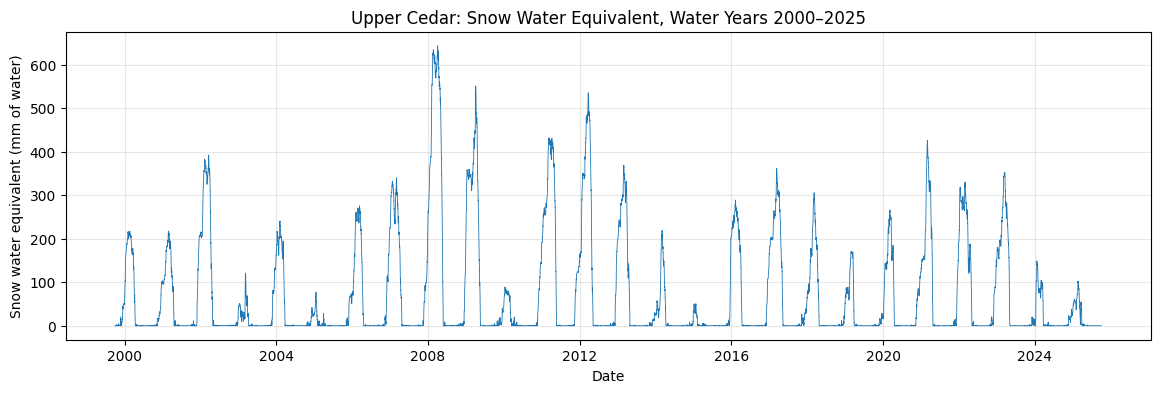

In [8]:
from io import StringIO
import time as pytime   # for short pauses between requests

def fetch_swe(start, end, lat=47.32, lon=-121.45):
    """Fetch hourly SWE for one time range and return it as a pandas Series."""
    params = {
        "data": "NLDAS_NOAH0125_H_2_0_SWE",    # dataset + variable
        "location": f"[{lat},{lon}]",          # latitude, longitude
        "time": f"{start}/{end}",              # time range
        "version": "2.0",
    }
    headers = {"Authorization": f"Bearer {token}"}   # send the token
    r = requests.get("https://api.giovanni.earthdata.nasa.gov/timeseries",
                     params=params, headers=headers, timeout=300)
    r.raise_for_status()                       # stop with an error if it failed

    # Skip the header info and read from the "Timestamp" line onward
    lines = r.text.splitlines()
    start_line = next(i for i, l in enumerate(lines) if l.startswith("Timestamp"))
    chunk = pd.read_csv(StringIO("\n".join(lines[start_line:])))
    chunk.columns = ["time", "swe_mm"]         # shorter column names
    chunk["time"] = pd.to_datetime(chunk["time"])
    return chunk.set_index("time")["swe_mm"]

# ---- THE LOOP: fetch 5 water years at a time, WY2000 (Oct 1999) to WY2025 ----
pieces = []
for start_year in range(1999, 2025, 5):
    end_year = min(start_year + 5, 2025)
    start = f"{start_year}-10-01T00:00:00"
    end = f"{end_year}-09-30T23:00:00"
    print(f"Fetching {start[:10]} to {end[:10]}...")
    pieces.append(fetch_swe(start, end))
    pytime.sleep(1)                            # be polite to NASA's server

# Combine all chunks into one series and clean it
swe = pd.concat(pieces).sort_index()
swe = swe[~swe.index.duplicated()]             # drop any overlapping hours
swe = swe.replace(-9999, float("nan"))         # -9999 means no data

print("Total rows:", len(swe))
print("From", swe.index.min(), "to", swe.index.max())
print("Missing values:", swe.isna().sum())

# Chart the full record
plt.figure(figsize=(14, 4))
plt.plot(swe.index, swe.values, linewidth=0.6)
plt.title("Upper Cedar: Snow Water Equivalent, Water Years 2000–2025")
plt.ylabel("Snow water equivalent (mm of water)")
plt.xlabel("Date")
plt.grid(alpha=0.3)
plt.show()